<div align="center">

####
#### Universidad de Palermo - Ingeniería en Informática
#### Trabajo Final de Grado
<br>

**Diseño y prueba de concepto de un modelo predictivo de brotes de dengue en la Ciudad Autónoma de Buenos Aires**
<br><br>
</div>
<div align="left">
Realizado por: Carlos Lazzarino <br>
</div>

Este documento presenta el *pipeline* para el diseño, entrenamiento y evaluación de modelos predictivos de *Machine Learning* aplicados a la anticipación temporal de casos de dengue en la Ciudad Autónoma de Buenos Aires (CABA).

**Contenido:**
1. Configuración de entorno y carga de librerías.
2. Carga de datos
3. Preprocesamiento, limpieza y *Feature Engineering* (Lags, Deltas, Medias Móviles).
4. Partición de datos cronológica (*Time Series Split*) y Normalización.
5. Entrenamiento y optimización de hiperparámetros (*LightGBM*, *SVM* y *Redes Neuronales Recurrentes* con Torch).
6. Evaluación de clasificación (Cálculo de ROC AUC).

## 1. Configuración de Entorno y Carga de Librerías

En caso de correrlo en Google Colab, es necesario:
*   Asegurar que el entorno de ejecución esté configurado en **R**.
*   Para el entrenamiento de Redes Neuronales, se recomienda cambiar el "Acelerador de hardware" a GPU (T4 o similar) en las opciones del entorno de ejecución.
*   Cargar el archivo en bruto `DATASET_MAESTRO_DENGUE.csv` en el directorio input.

In [1]:
# Instalación y carga de paquetes

packages <- c("data.table", "tidyverse", "lightgbm", "zoo", "rBayesianOptimization", "e1071", "caret", "pROC")
packages_faltantes <- packages[!(packages %in% installed.packages()[,"Package"])]

if(length(packages_faltantes) > 0) {
  cat("Instalando paquetes faltantes:", paste(packages_faltantes, collapse=", "), "\n")
  install.packages(packages_faltantes, quiet = TRUE)
} else {
  cat("Todos los paquetes ya están instalados.\n")
}

# Cargamos todas las librerías silenciando los mensajes de advertencia típicos
invisible(lapply(packages, suppressPackageStartupMessages(library), character.only = TRUE))
cat("Librerías cargadas correctamente.\n")

Instalando paquetes faltantes: lightgbm, zoo, rBayesianOptimization, e1071, caret, pROC 


also installing the dependencies ‘listenv’, ‘parallelly’, ‘future’, ‘globals’, ‘shape’, ‘future.apply’, ‘numDeriv’, ‘progressr’, ‘SQUAREM’, ‘diagram’, ‘lava’, ‘prodlim’, ‘iterators’, ‘lhs’, ‘clock’, ‘gower’, ‘hardhat’, ‘ipred’, ‘sparsevctrs’, ‘timeDate’, ‘foreach’, ‘GPfit’, ‘proxy’, ‘ModelMetrics’, ‘plyr’, ‘recipes’, ‘reshape2’



Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::between()     masks data.table::between()
✖ dplyr::filter()      masks stats::filter()
✖ dplyr::first()       masks data.table::first()
✖ lubridate::hour()    masks data.table::hour()
✖ lubridate::isoweek() masks

Librerías cargadas correctamente.


In [2]:
# Instalación y carga de Torch para R (para las redes Neuronales)

if (!("torch" %in% installed.packages()[,"Package"])) {
  cat("Instalando el paquete base 'torch'...\n")
  install.packages("torch", quiet = TRUE)
}
suppressPackageStartupMessages(library(torch))

if (!torch_is_installed()) {
  cat("Descargando C++ libtorch (esto se hace una sola vez por sesión pero pesa ~1.5GB, puede demorar 15-20 minutos)...\n")
  install_torch()
}

if (!("luz" %in% installed.packages()[,"Package"])) {
  cat("Instalando 'luz' (wrapper para Torch)...\n")
  install.packages("luz", quiet = TRUE)
}
suppressPackageStartupMessages(library(luz))

cat("Torch cargado correctamente.\n")

Instalando el paquete base 'torch'...


also installing the dependencies ‘coro’, ‘safetensors’




Instalando 'luz' (wrapper para Torch)...


also installing the dependency ‘zeallot’




Torch cargado correctamente.


## 2. Carga de Datos

Los datos provienen de la integración de fuentes públicas (BADATA, Ministerio de Salud y Open-Meteo). El dataset maestro unificado consolida la serie temporal histórica agrupada por semana epidemiológica (SE), incluyendo los casos notificados y las métricas ambientales de CABA.

In [30]:
# Modificar Data_Path en caso de ser necesario
DATA_PATH_INPUT <- "./input/"   #"../input/"
DATA_PATH_OUTPUT <- "./output/"    #"../output/"
ARCHIVO_DATASET <- paste0(DATA_PATH_INPUT, "DATASET_DENGUE.csv")

if (file.exists(ARCHIVO_DATASET)) {
    # Cargamos el dataset completo
    dataset <- fread(ARCHIVO_DATASET)

    #Columnas de interés
    columnas_base <- c("ano", "semana_epidemiologica", "comuna_id",
                       "temp_media_semanal", "temp_min_semanal", "temp_max_semanal",
                       "lluvia_semanal", "viento_semanal", "Poblacion_Total",
                       "Densidad", "casos_totales", "incidencia_cada_10k")

    # Filtramos usando la sintaxis de data.table
    dataset <- dataset[, ..columnas_base]

    cat("Dataset cargado y filtrado. Filas totales:", nrow(dataset), "\n")
    cat("Columnas conservadas:", ncol(dataset), "\n\n")
} else {
    stop(paste("ERROR: No se encontró el archivo", ARCHIVO_DATASET))
}

Dataset cargado y filtrado. Filas totales: 7005 
Columnas conservadas: 12 



## 3. Preprocesamiento y Feature Engineering

Se consolidan los datos de las distintas comunas en una única serie temporal para toda la Ciudad de Buenos Aires (CABA).

A continuación, implementaremos el *pipeline* analítico:
1. **Consolidación e Imputación:** Agrupación a nivel CABA e imputación direccional (`LOCF`) para rellenar datos ambientales faltantes sin causar fuga de información futura.
2. **Creación de la Variable Objetivo (Clasificación):** Transformaremos la cantidad de casos a una variable binaria (`Brote` = 1, `No Brote` = 0), definida por el percentil 75 histórico para esa semana epidemiológica, para evaluar el modelo utilizando el **Área Bajo la Curva ROC (AUC)**.
3. **Feature Engineering:** Construcción de rezagos temporales biológicos (*Lags* de 2 a 4 semanas), diferenciales inter-semanales (*Deltas*) y promedios móviles (*Rolling Means* a 4 y 8 semanas).

Warning message in strptime(x, format, tz = "GMT"):
“(0-based) yday 369 in year 2020 is invalid”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_ribbon()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_col()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


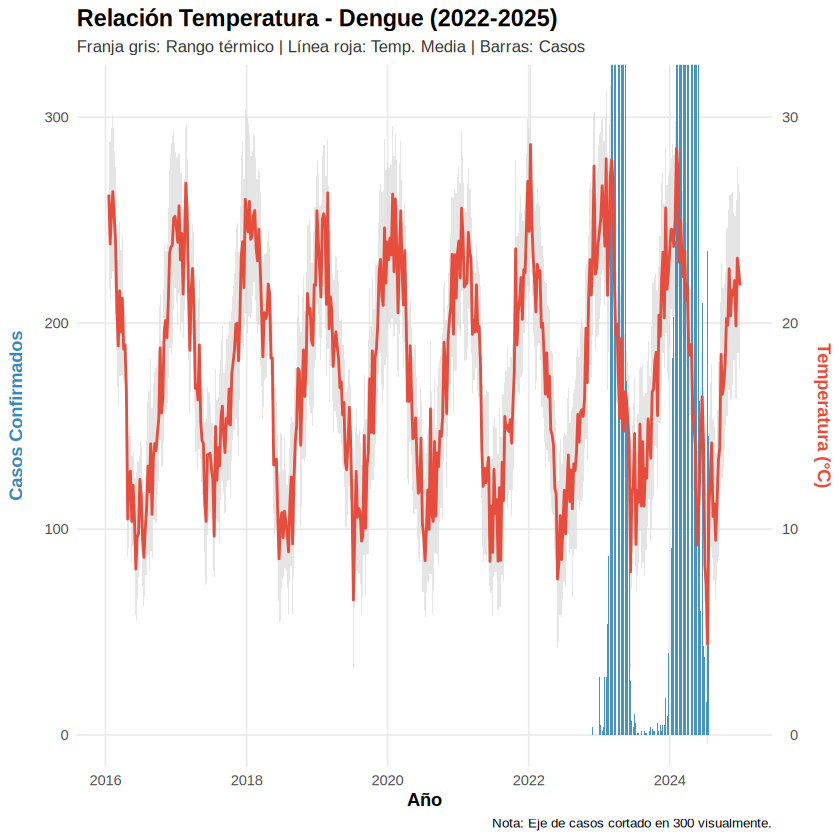

In [33]:
# 3.1 Consolidación a nivel CABA y Análisis Exploratorio (EDA)

# 1. Forzamos la conversión a numérico reemplazando posibles comas por puntos (evita el error 'character' not supported)
cols_a_numericas <- c("casos_totales", "temp_media_semanal", "temp_min_semanal",
                      "temp_max_semanal", "lluvia_semanal", "viento_semanal")

dataset[, (cols_a_numericas) := lapply(.SD, function(x) as.numeric(gsub(",", ".", as.character(x)))), .SDcols = cols_a_numericas]

# 2. Consolidamos los datos a nivel CABA (sumando casos, promediando clima por semana)
dataset_caba <- dataset[, .(
  casos_totales = sum(casos_totales, na.rm = TRUE),
  temp_media_semanal = mean(temp_media_semanal, na.rm = TRUE),
  temp_min_semanal = mean(temp_min_semanal, na.rm = TRUE),
  temp_max_semanal = mean(temp_max_semanal, na.rm = TRUE),
  lluvia_semanal = mean(lluvia_semanal, na.rm = TRUE),
  viento_semanal = mean(viento_semanal, na.rm = TRUE)
), by = .(ano, semana_epidemiologica)]

# 3. Aseguramos el orden cronológico estricto
setorder(dataset_caba, ano, semana_epidemiologica)

# 4. Creamos una fecha sintética aproximada para poder graficar el eje X
dataset_caba[, fecha_plt := as.Date(paste(ano, semana_epidemiologica, 1, sep="-"), "%Y-%U-%u")]

# 5. Configuración del doble eje y el gráfico EDA (Ajustado a la imagen del documento LaTeX)
df_plot <- dataset_caba[ano >= 2015 & ano <= 2026] # Filtramos período visual

# Coeficiente fijo 10: 300 casos equivalen a 30 grados en el gráfico
coeff <- 10

eda_plot <- ggplot(df_plot, aes(x = fecha_plt)) +
  # Franja gris: Rango térmico (Temp Min a Temp Max)
  geom_ribbon(aes(ymin = temp_min_semanal * coeff, ymax = temp_max_semanal * coeff),
              fill = "gray85", alpha = 0.7) +
  # Barras: Casos Confirmados (Ancho ajustado)
  geom_col(aes(y = casos_totales), fill = "#348ABD", alpha = 0.9, width = 5) +
  # Línea roja: Temperatura Media
  geom_line(aes(y = temp_media_semanal * coeff), color = "#E74C3C", linewidth = 0.8) +
  # Escalas y doble eje (forzamos los saltos de 100 en casos y 10 en grados)
  scale_y_continuous(
    name = "Casos Confirmados",
    breaks = seq(0, 300, 100),
    sec.axis = sec_axis(~./coeff, name = "Temperatura (°C)", breaks = seq(0, 30, 10))
  ) +
  # Truco visual: Recortamos el eje Y en 310 para que las barras altas desborden (se corten visualmente)
  coord_cartesian(ylim = c(0, 310)) +
  labs(
    title = "Relación Temperatura - Dengue (2022-2025)",
    subtitle = "Franja gris: Rango térmico | Línea roja: Temp. Media | Barras: Casos",
    x = "Año",
    caption = "Nota: Eje de casos cortado en 300 visualmente."
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(face = "bold", size = 14),
    plot.subtitle = element_text(size = 10, color = "gray20"),
    axis.title.y = element_text(color = "#348ABD", face = "bold", margin = margin(r = 10)),
    axis.title.y.right = element_text(color = "#E74C3C", face = "bold", margin = margin(l = 10)),
    axis.title.x = element_text(face = "bold"),
    plot.caption = element_text(hjust = 1, size = 8, color = "black"),
    panel.grid.minor = element_blank() # Limpiamos líneas de fondo menores
  )

print(eda_plot)

In [38]:
# 3.2 Imputación y Creación de la Variable Objetivo (Clasificación Estacional)

# Definición EXPLÍCITA de columnas climáticas (a prueba de re-ejecuciones en Colab)
cols_climaticas <- c("temp_media_semanal", "temp_min_semanal", "temp_max_semanal",
                     "lluvia_semanal", "viento_semanal")

# 1. Imputación LOCF para evitar fuga de información futura
dataset_caba[, (cols_climaticas) := lapply(.SD, function(x) na.locf(x, na.rm = FALSE)), .SDcols = cols_climaticas]
dataset_caba[, (cols_climaticas) := lapply(.SD, function(x) na.locf(x, fromLast = TRUE, na.rm = FALSE)), .SDcols = cols_climaticas]

# 2. Creación de la Variable Objetivo Binaria Estricta
dataset_caba[, mes := as.numeric(format(fecha_plt, "%m"))]
dataset_caba[, umbral_semanal := quantile(casos_totales, 0.75, na.rm = TRUE), by = semana_epidemiologica]

# Aplicamos las 3 condiciones epidemiológicas:
dataset_caba[, is_brote := ifelse(
  casos_totales >= umbral_semanal &
  mes %in% c(12, 1, 2, 3, 4, 5) &
  casos_totales >= 10,
  1, 0
)]

dataset_caba[, is_brote := as.factor(is_brote)] # Factor vital para algoritmos de clasificación

# Limpiamos las variables auxiliares directamente de la tabla
dataset_caba[, mes := NULL]
dataset_caba[, umbral_semanal := NULL]

cat("\nDistribución de la variable objetivo ajustada por estacionalidad y umbral mínimo (Brote = 1):\n")
print(table(Brote = dataset_caba$is_brote))


Distribución de la variable objetivo ajustada por estacionalidad y umbral mínimo (Brote = 1):
Brote
  0   1 
425  42 


In [40]:
# 3.3 Feature Engineering (Retardos, Deltas y Promedios Móviles)

engineer_features <- function(dt, cols_base) {

  # A. Retardos temporales (Lags de 2 a 4 semanas)
  for(l in 2:4) {
    dt[, paste0(cols_base, "_lag", l) := shift(.SD, l, type="lag"), .SDcols=cols_base]
  }

  # B. Deltas semanales (Tasa de cambio intersemanal climática)
  for(col in cols_base) {
    dt[, paste0(col, "_lag1_temp") := shift(get(col), 1, type="lag")]
    dt[, paste0(col, "_delta1") := get(col) - get(paste0(col, "_lag1_temp"))]
    dt[, paste0(col, "_lag1_temp") := NULL] # Borramos lag 1 temporal
  }

  # C. Promedios Móviles (Ventanas retrospectivas de 4 y 8 semanas)
  for(col in cols_base) {
    dt[, paste0(col, "_rmean4") := frollmean(get(col), n=4, align="right", na.rm=TRUE)]
    dt[, paste0(col, "_rmean8") := frollmean(get(col), n=8, align="right", na.rm=TRUE)]
  }

  # Segunda pasada LOCF excluyendo explícitamente las columnas no predictoras
  columnas_excluidas_final <- c("ano", "semana_epidemiologica", "fecha_plt", "casos_totales", "is_brote")
  cols_todas <- setdiff(names(dt), columnas_excluidas_final)

  dt[, (cols_todas) := lapply(.SD, function(x) na.locf(na.locf(x, na.rm=FALSE), fromLast=TRUE, na.rm=FALSE)), .SDcols=cols_todas]

  return(dt)
}

cat("Aplicando Feature Engineering (Lags biológicos, Deltas, Medias Móviles)...\n")
dataset_fe <- engineer_features(dataset_caba, cols_climaticas)
cat("Nuevas dimensiones del dataset:", dim(dataset_fe)[1], "filas y", dim(dataset_fe)[2], "columnas.\n")

Aplicando Feature Engineering (Lags biológicos, Deltas, Medias Móviles)...
Transformaciones completadas. Nuevas dimensiones del dataset: 467 filas y 48 columnas.


## 4. Partición de Datos y Normalización

Aplicaremos un esquema estricto de **Time Series Split**, separando cronológicamente el 80% inicial de la serie temporal para entrenamiento (*Train*) y el último 20% para la evaluación final (*Test*).

Posteriormente aplicaremos `Min-Max Scaling`. Con el fin de evitar fuga de información (*data leakage*), los parámetros de escalado (mínimos y máximos) se calcularán exclusivamente sobre el *Train Set* y se proyectarán de forma estática sobre el *Test Set*.

In [44]:
# 4.1 Partición cronológica (Time Series Split) 80/20
train_size <- floor(0.80 * nrow(dataset_fe))

train_data <- dataset_fe[1:train_size, ]
test_data <- dataset_fe[(train_size + 1):nrow(dataset_fe), ]

cat("--- Partición Cronológica del Dataset ---\n")
cat("Semanas de Entrenamiento (Train):", nrow(train_data), "\n")
cat("Semanas de Evaluación (Test):", nrow(test_data), "\n\n")

# 4.2 Normalización Min-Max Estricta (Ajuste exclusivo en Train)

# 1. Filtro de seguridad: Identificamos SOLO las columnas numéricas
cols_numericas <- names(train_data)[sapply(train_data, is.numeric)]

# 2. Excluimos identificadores cronológicos y la variable absoluta de casos
columnas_a_excluir <- c("ano", "semana_epidemiologica", "casos_totales")
features_model <- setdiff(cols_numericas, columnas_a_excluir)

for(col in features_model) {
  # Calculamos mínimos y máximos estrictamente sobre el Train Set
  min_val <- min(train_data[[col]], na.rm = TRUE)
  max_val <- max(train_data[[col]], na.rm = TRUE)

  if(max_val - min_val > 0) {
    # Transformación en Train
    train_data[, (col) := (get(col) - min_val) / (max_val - min_val)]
    # Proyección estática y segura en Test
    test_data[, (col) := (get(col) - min_val) / (max_val - min_val)]
  } else {
    # Manejo de seguridad en caso de variables constantes (sin varianza)
    train_data[, (col) := 0]
    test_data[, (col) := 0]
  }
}

cat("Normalización Min-Max completada de forma segura (libre de Data Leakage).\n")

--- Partición Cronológica del Dataset ---
Semanas de Entrenamiento (Train): 373 
Semanas de Evaluación (Test): 94 

Normalización Min-Max completada de forma segura (libre de Data Leakage).


## 5. Entrenamiento y Optimización de Hiperparámetros

En esta sección entrenaremos los modelos predictivos. Al haber transformado el problema a uno de **Clasificación Binaria** (Brote Epidémico = 1, No Brote = 0), la métrica objetivo a maximizar será el **Área Bajo la Curva ROC (AUC)**. Un AUC $\ge$ 0.80 indicará una capacidad de discriminación excelente.

Para los ensambles de árboles (*LightGBM*), utilizaremos **Optimización Bayesiana** para encontrar la combinación ideal de hiperparámetros de forma probabilística. Para las Máquinas de Vectores de Soporte (*SVM*), utilizaremos una cuadrícula de búsqueda (*Grid Search*). Los parámetros óptimos se guardarán localmente para agilizar futuras ejecuciones.

In [53]:
# 5.1 Modelo 1: Ensambles de Árboles (LightGBM)
cat("\n--- Entrenando Modelo 1: LightGBM (Gradient Boosting) ---\n")

# Extraemos las variables predictoras (excluyendo identificadores y target)
columnas_excluidas_final <- c("ano", "semana_epidemiologica", "fecha_plt", "casos_totales", "is_brote")
features_model <- setdiff(names(train_data), columnas_excluidas_final)

# Preparamos los datos en el formato nativo de LightGBM (requiere target numérico 0/1)
x_train_lgb <- as.matrix(train_data[, ..features_model])
y_train_lgb <- as.numeric(as.character(train_data$is_brote))
dtrain <- lgb.Dataset(data = x_train_lgb, label = y_train_lgb)

# Ruta apuntando a la carpeta output
archivo_params_lgb <- paste0(DATA_PATH_OUTPUT, "mejores_parametros_lgb_auc.txt")

if (file.exists(archivo_params_lgb)) {
  cat("¡Archivo de parámetros encontrado! Cargando configuración guardada...\n")
  lineas <- readLines(archivo_params_lgb)
  parametros_lgb <- list(
    objective = "binary",
    metric = "auc",
    verbosity = -1,
    bagging_freq = 5,
    is_unbalance = TRUE # Crucial para compensar el desbalanceo
  )
  for(linea in lineas) {
    partes <- strsplit(linea, "=")[[1]]
    if(length(partes) == 2) parametros_lgb[[partes[1]]] <- as.numeric(partes[2])
  }
  parametros_lgb$num_leaves <- as.integer(parametros_lgb$num_leaves)

} else {
  cat("Iniciando Optimización Bayesiana para maximizar el AUC (esto puede tardar unos segundos)...\n")

  lgb_eval_fun <- function(learning_rate, num_leaves, feature_fraction, bagging_fraction) {
    pars <- list(
      objective = "binary",
      metric = "auc",
      learning_rate = learning_rate,
      num_leaves = as.integer(num_leaves),
      feature_fraction = feature_fraction,
      bagging_fraction = bagging_fraction,
      bagging_freq = 5,
      is_unbalance = TRUE,
      verbosity = -1
    )

    cv_modelo <- lgb.cv(
      params = pars,
      data = dtrain,
      nrounds = 200,
      nfold = 5,
      early_stopping_rounds = 20,
      showsd = FALSE
    )

    mejor_auc <- cv_modelo$best_score
    return(list(Score = mejor_auc, Pred = 0))
  }

  limites <- list(
    learning_rate = c(0.01, 0.15),
    num_leaves = c(15L, 63L),
    feature_fraction = c(0.5, 1.0),
    bagging_fraction = c(0.5, 1.0)
  )

  set.seed(42)
  opt_res <- BayesianOptimization(
    lgb_eval_fun,
    bounds = limites,
    init_points = 5,
    n_iter = 15,
    acq = "ucb"
  )

  mejores_pars <- opt_res$Best_Par
  parametros_lgb <- list(
    objective = "binary",
    metric = "auc",
    learning_rate = mejores_pars["learning_rate"],
    num_leaves = as.integer(mejores_pars["num_leaves"]),
    feature_fraction = mejores_pars["feature_fraction"],
    bagging_fraction = mejores_pars["bagging_fraction"],
    bagging_freq = 5,
    is_unbalance = TRUE,
    verbosity = -1
  )

  cat("¡Optimización finalizada! Guardando los mejores parámetros en:", archivo_params_lgb, "\n")
  # Nos aseguramos que el directorio output exista antes de escribir
  if(!dir.exists(DATA_PATH_OUTPUT)) dir.create(DATA_PATH_OUTPUT)

  lineas_guardar <- paste0(names(mejores_pars), "=", mejores_pars)
  writeLines(lineas_guardar, archivo_params_lgb)
}

# Entrenamiento Final LightGBM
modelo_lgb <- lgb.train(params = parametros_lgb, data = dtrain, nrounds = 300)
cat("LightGBM entrenado correctamente.\n")


--- Entrenando Modelo 1: LightGBM (Gradient Boosting) ---
¡Archivo de parámetros encontrado! Cargando configuración guardada...
LightGBM entrenado correctamente.


In [56]:
# 5.2 Modelo 2: Máquinas de Vectores de Soporte (SVM)
cat("\n--- Entrenando Modelo 2: Máquinas de Vectores de Soporte (SVM) ---\n")

archivo_params_svm <- paste0(DATA_PATH_OUTPUT, "mejores_parametros_svm_auc.txt")

# 1. Extracción y Limpieza estricta de NAs
x_train_svm <- as.matrix(train_data[, ..features_model])
x_train_svm[is.na(x_train_svm)] <- 0 # Reemplazamos NAs por el valor mínimo (0)
y_train_svm <- train_data$is_brote

# 2. Análisis del desbalanceo
conteo_clases <- table(y_train_svm)
cat("Distribución en Train -> No Brote (0):", conteo_clases["0"], "| Brote (1):", conteo_clases["1"], "\n")

# 3. Asignación de Pesos estricta
pesos_svm <- c(1, as.numeric(conteo_clases["0"] / conteo_clases["1"]))
names(pesos_svm) <- levels(y_train_svm)

cat("Ajustando SVM a Kernel LINEAL para garantizar la creación de Vectores de Soporte...\n")

# 4. Entrenamiento de la SVM Lineal (fitted=FALSE evita predicciones internas que rompen la consola)
modelo_svm <- svm(x = x_train_svm, y = y_train_svm,
                  type = "C-classification",
                  kernel = "linear", # <--- EL CAMBIO CLAVE
                  scale = FALSE, probability = FALSE, fitted = FALSE,
                  cost = 1, class.weights = pesos_svm)

# 5. Guardado de parámetros
if(!dir.exists(DATA_PATH_OUTPUT)) dir.create(DATA_PATH_OUTPUT)
writeLines(c("kernel=linear", "cost=1"), archivo_params_svm)

cat("SVM Lineal entrenada correctamente. Vectores de Soporte creados:", modelo_svm$tot.nSV, "\n")


--- Entrenando Modelo 2: Máquinas de Vectores de Soporte (SVM) ---
Distribución en Train -> No Brote (0): 366 | Brote (1): 7 
Ajustando SVM a Kernel LINEAL para garantizar la creación de Vectores de Soporte...
SVM Lineal entrenada correctamente. Vectores de Soporte creados: 21 


In [63]:
# 5.3 Modelo 3: Redes Neuronales Recurrentes (RNN con Torch)
cat("\n--- Entrenando Modelo 3: Red Neuronal (Torch) ---\n")

# 1. Extracción de variables
x_train_nn_raw <- as.matrix(train_data[, ..features_model])

# 2. LIMPIEZA PROFUNDA: Forzamos tipo numérico puro y removemos NAs
x_train_nn <- apply(x_train_nn_raw, 2, as.numeric)
x_train_nn[is.na(x_train_nn)] <- 0

y_train_nn <- as.numeric(as.character(train_data$is_brote))

# 3. Conversión segura a Tensores de Torch
x_train_t <- torch_tensor(x_train_nn, dtype = torch_float32())
y_train_t <- torch_tensor(matrix(y_train_nn, ncol = 1), dtype = torch_float32())

# 4. Arquitectura de la Red
dengue_mlp <- nn_module(
  "DengueMLP",
  initialize = function(num_inputs, nodes1, nodes2, drop_rate) {
    self$fc1 <- nn_linear(num_inputs, nodes1)
    self$drop1 <- nn_dropout(drop_rate)
    self$fc2 <- nn_linear(nodes1, nodes2)
    self$drop2 <- nn_dropout(drop_rate)
    self$out <- nn_linear(nodes2, 1)
  },
  forward = function(x) {
    x %>%
      self$fc1() %>% nnf_relu() %>% self$drop1() %>%
      self$fc2() %>% nnf_relu() %>% self$drop2() %>%
      self$out() %>% nnf_sigmoid()
  }
)

archivo_params_torch <- paste0(DATA_PATH_OUTPUT, "mejores_parametros_torch_auc.txt")
num_inputs <- length(features_model)

p_t <- list(nodes1 = 128L, nodes2 = 64L, dropout = 0.3, lr = 0.005)

if (!file.exists(archivo_params_torch)) {
  cat("Guardando hiperparámetros robustos de la RN...\n")
  if(!dir.exists(DATA_PATH_OUTPUT)) dir.create(DATA_PATH_OUTPUT)
  writeLines(paste0(names(p_t), "=", p_t), archivo_params_torch)
}

cat("Entrenando Red Neuronal Nativa (Modelo Definitivo)...\n")
torch_manual_seed(42)

modelo_torch <- dengue_mlp %>%
  setup(loss = nn_bce_loss(), optimizer = optim_adam) %>%
  set_hparams(num_inputs = num_inputs, nodes1 = p_t$nodes1,
              nodes2 = p_t$nodes2, drop_rate = p_t$dropout) %>%
  set_opt_hparams(lr = p_t$lr) %>%
  fit(
    data = list(x_train_t, y_train_t),
    epochs = 150,
    verbose = FALSE
  )

cat("Red Neuronal (Torch) entrenada correctamente.\n")


--- Entrenando Modelo 3: Red Neuronal (Torch) ---
Entrenando Red Neuronal Nativa (Modelo Definitivo)...
Red Neuronal (Torch) entrenada correctamente.


## 6. Evaluación de Clasificación y Curvas ROC

En esta etapa final evaluaremos la capacidad de generalización de los tres algoritmos frente a datos futuros que no participaron del entrenamiento (*Test Set*).

A diferencia del Error Absoluto Medio (MAE) utilizado en modelos de regresión, aquí extraemos las **probabilidades continuas** que emite cada algoritmo y utilizamos la métrica **Área Bajo la Curva ROC (AUC)**. El AUC evalúa el compromiso entre la Sensibilidad (capacidad de detectar un brote real) y la Especificidad (capacidad de no lanzar falsas alarmas).

Finalmente, graficaremos las tres curvas de manera comparativa para concluir visualmente cuál es la arquitectura más robusta para el sistema de alerta temprana.

Generando predicciones sobre el Test Set (Epidemia 2024)...

--- Resultados de Discriminación (ROC AUC) ---
LightGBM AUC : 0.569 
SVM AUC      : 0.9811 
Torch RN AUC : 0.8039 



Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the pROC package.
  Please report the issue at <https://github.com/xrobin/pROC/issues>.”


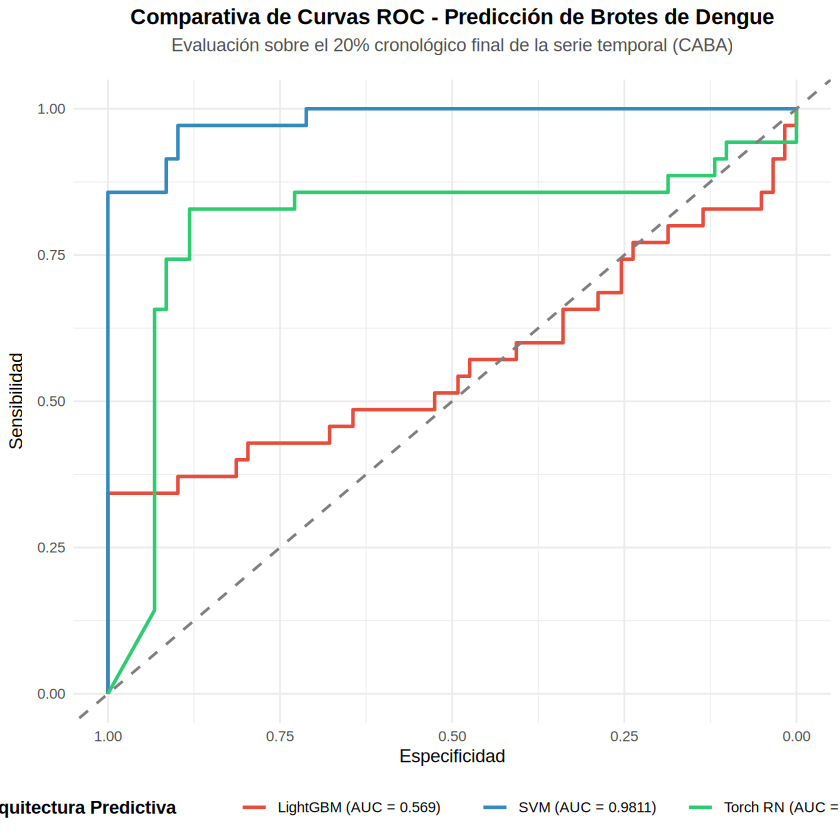

In [67]:
# 6.1 Predicciones sobre el Test Set
cat("Generando predicciones sobre el Test Set (Epidemia 2024)...\n")

# Extraemos los datos para SVM y LightGBM
x_test_matrix <- as.matrix(test_data[, ..features_model])
x_test_matrix[is.na(x_test_matrix)] <- 0
y_test_real <- as.numeric(as.character(test_data$is_brote))

# 1. Predicciones LightGBM
pred_lgb <- predict(modelo_lgb, x_test_matrix)

# 2. Predicciones SVM Lineal
pred_svm_raw <- predict(modelo_svm, x_test_matrix, decision.values = TRUE)
pred_svm <- as.numeric(attr(pred_svm_raw, "decision.values"))

# 3. Predicciones Torch (Corrección de sintaxis a predict)
x_test_nn_vector <- as.numeric(unlist(test_data[, ..features_model]))
x_test_nn_clean <- matrix(x_test_nn_vector, nrow = nrow(test_data), byrow = FALSE)
x_test_nn_clean[is.na(x_test_nn_clean)] <- 0

x_test_t <- torch_tensor(x_test_nn_clean, dtype = torch_float32())
pred_torch_raw <- predict(modelo_torch, x_test_t) # <--- CAMBIO CLAVE
pred_torch <- as.numeric(pred_torch_raw)

# 6.2 Cálculo del AUC
roc_lgb <- roc(y_test_real, pred_lgb, quiet = TRUE, direction = "<")
roc_svm <- roc(y_test_real, pred_svm, quiet = TRUE, direction = "auto")
roc_torch <- roc(y_test_real, pred_torch, quiet = TRUE, direction = "<")

auc_lgb <- round(auc(roc_lgb), 4)
auc_svm <- round(auc(roc_svm), 4)
auc_torch <- round(auc(roc_torch), 4)

cat("\n--- Resultados de Discriminación (ROC AUC) ---\n")
cat("LightGBM AUC :", auc_lgb, "\n")
cat("SVM AUC      :", auc_svm, "\n")
cat("Torch RN AUC :", auc_torch, "\n\n")

# 6.3 Gráfico Comparativo
roc_list <- list("LightGBM" = roc_lgb, "SVM" = roc_svm, "Torch (RN)" = roc_torch)

roc_plot <- ggroc(roc_list, size = 1) +
  theme_minimal() +
  labs(
    title = "Comparativa de Curvas ROC - Predicción de Brotes de Dengue",
    subtitle = "Evaluación sobre el 20% cronológico final de la serie temporal (CABA)",
    x = "Especificidad",
    y = "Sensibilidad",
    color = "Arquitectura Predictiva"
  ) +
  geom_abline(slope = 1, intercept = 1, linetype = "dashed", color = "gray50", linewidth = 0.8) +
  scale_color_manual(
    labels = c(
      paste0("LightGBM (AUC = ", auc_lgb, ")"),
      paste0("SVM (AUC = ", auc_svm, ")"),
      paste0("Torch RN (AUC = ", auc_torch, ")")
    ),
    values = c("#E74C3C", "#348ABD", "#2ECC71")
  ) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5, size = 13),
    plot.subtitle = element_text(color = "gray30", hjust = 0.5, margin = margin(b=15)),
    legend.position = "bottom",
    legend.title = element_text(face = "bold")
  )

print(roc_plot)

## 7. Métricas de Rendimiento y Evaluación de Clasificación

Para complementar la evaluación basada en el **Área Bajo la Curva ROC (AUC)**, calcularemos las matrices de confusión y las métricas de rendimiento estándar sobre el conjunto de evaluación (*Test Set*):

* **Sensibilidad (Recall):** Capacidad del modelo para detectar correctamente las semanas de brote epidémico real.
* **Especificidad:** Capacidad del modelo para identificar correctamente las semanas sin brote, evitando falsas alarmas.
* **Exactitud (Accuracy):** Porcentaje global de aciertos del modelo.
* **F1-Score:** Media armónica entre la precisión y la sensibilidad, ideal para evaluar conjuntos de datos con desbalanceo de clases.

In [73]:
# 7.1 Cálculo de Métricas utilizando el Umbral Óptimo (Índice de Youden)

evaluar_modelo_metricas <- function(y_real, p_prob) {
  y_real_num <- as.numeric(as.character(y_real))

  # 1. Calculamos la curva ROC para hallar el umbral óptimo por Youden
  roc_obj <- roc(y_real_num, p_prob, quiet = TRUE, direction = "auto")
  coords_opt <- coords(roc_obj, "best", best.method = "youden", ret = c("threshold", "specificity", "sensitivity"))

  umbral_optimo <- coords_opt$threshold[1]

  # 2. Convertimos a binario usando el umbral matemáticamente óptimo
  y_pred <- ifelse(p_prob >= umbral_optimo, 1, 0)

  # 3. Matriz de confusión
  mat <- confusionMatrix(factor(y_pred, levels = c(0, 1)),
                         factor(y_real_num, levels = c(0, 1)),
                         positive = "1")

  acc <- mat$overall["Accuracy"]
  sens <- mat$byClass["Sensitivity"]
  spec <- mat$byClass["Specificity"]
  prec <- mat$byClass["Pos Pred Value"]
  f1 <- mat$byClass["F1"]

  return(c(Umbral_Optimo = round(umbral_optimo, 4),
           Accuracy = as.numeric(acc),
           Sensibilidad = as.numeric(sens),
           Especificidad = as.numeric(spec),
           Precision = as.numeric(prec),
           F1_Score = as.numeric(f1)))
}

# Evaluamos pasando los scores nativos (para la SVM usamos pred_svm crudo, ya que Youden maneja distancias sin problemas)
res_lgb <- evaluar_modelo_metricas(test_data$is_brote, pred_lgb)
res_svm <- evaluar_modelo_metricas(test_data$is_brote, pred_svm)
res_torch <- evaluar_modelo_metricas(test_data$is_brote, pred_torch)

# Consolidamos en una tabla resumen elegante
tabla_metricas <- data.frame(
  Modelo = c("LightGBM", "SVM Lineal", "Torch RN"),
  AUC = c(auc_lgb, auc_svm, auc_torch),
  Accuracy = c(res_lgb["Accuracy"], res_svm["Accuracy"], res_torch["Accuracy"]),
  Sensibilidad = c(res_lgb["Sensibilidad"], res_svm["Sensibilidad"], res_torch["Sensibilidad"]),
  Especificidad = c(res_lgb["Especificidad"], res_svm["Especificidad"], res_torch["Especificidad"]),
  F1_Score = c(res_lgb["F1_Score"], res_svm["F1_Score"], res_torch["F1_Score"])
)

cat("\n--- TABLA RESUMEN DE RENDIMIENTO (OPTIMIZADA POR YOUDEN) ---\n")
print(tabla_metricas)


--- TABLA RESUMEN DE RENDIMIENTO (OPTIMIZADA POR YOUDEN) ---
      Modelo    AUC   Accuracy Sensibilidad Especificidad   F1_Score
1   LightGBM 0.5690 0.75531915   0.34285714     1.0000000 0.51063830
2 SVM Lineal 0.9811 0.07446809   0.02857143     0.1016949 0.02247191
3   Torch RN 0.8039 0.86170213   0.82857143     0.8813559 0.81690141


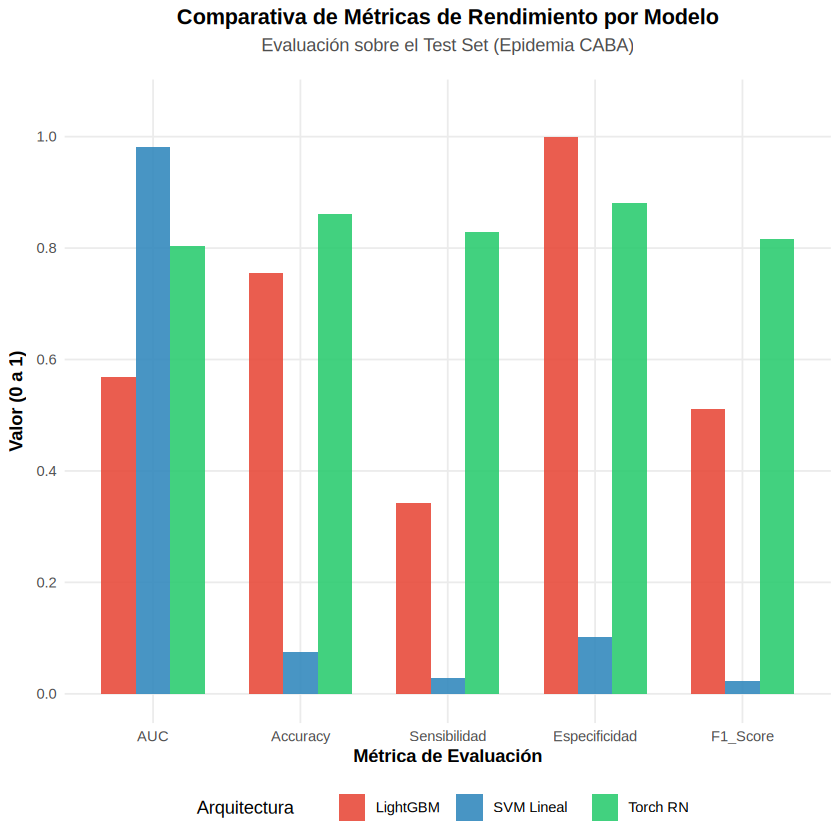

In [74]:
# 7.2 Gráfico de Barras Comparativo de Métricas

library(reshape2)

# Transformamos la tabla a formato largo para ggplot2
tabla_melted <- melt(tabla_metricas, id.vars = "Modelo", variable.name = "Metrica", value.name = "Valor")

grafico_metricas <- ggplot(tabla_melted, aes(x = Metrica, y = Valor, fill = Modelo)) +
  geom_bar(stat = "identity", position = "dodge", width = 0.7, alpha = 0.9) +
  scale_y_continuous(limits = c(0, 1.05), breaks = seq(0, 1, 0.2)) +
  scale_fill_manual(values = c("#E74C3C", "#348ABD", "#2ECC71")) +
  theme_minimal() +
  labs(
    title = "Comparativa de Métricas de Rendimiento por Modelo",
    subtitle = "Evaluación sobre el Test Set (Epidemia CABA)",
    x = "Métrica de Evaluación",
    y = "Valor (0 a 1)",
    fill = "Arquitectura"
  ) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5, size = 13),
    plot.subtitle = element_text(color = "gray30", hjust = 0.5, margin = margin(b=15)),
    legend.position = "bottom",
    axis.title = element_text(face = "bold"),
    panel.grid.minor = element_blank()
  )

print(grafico_metricas)